# BioCLIP basic text head + logit adjustment (Colab, standalone)

One run, trained with the group's **single training scheme** (`training_scheme.md`): guide.md run 2b. No LLM descriptions, no adapters, no CoOp/CSP/KgCoOp.

Two cosine heads `T_c`, `T_d` are **initialised from** the BioCLIP text embedding of the taxonomy prompt (`a photo of a {crop} leaf, {taxonomy}` / `a photo of a leaf with {disease}, {taxonomy}`), then trained. The text encoder is frozen. **The only change from the plain basic-text notebook is logit adjustment (Menon et al., ICLR 2021): during training, `tau * log(prior)` of the train class frequencies is added to the crop and disease logits before the cross-entropy. Validation, test and inference use the plain logits.** Epoch 0 is exactly BioCLIP zero-shot with this text, and is logged.

```
image (224) -> BioCLIP image encoder (frozen) -> v (512) -> N(v) -> Dropout 0.3 -> cos(., T_c) * logit_scale -> 55 crop logits
                                                                  \-> Dropout 0.3 -> cos(., T_d) * logit_scale -> 175 disease logits
T_c, T_d = free parameters, initialised from TextEncoder("a photo of a {crop} leaf, {taxonomy}")
```

**Scheme** and where each value comes from:

| Setting | Value | Source |
|---|---|---|
| Backbone | BioCLIP ViT-B/16, image and text encoders frozen, logit scale fixed to BioCLIP's | Stevens et al., CVPR 2024; frozen features / head-only start: Kumar et al., ICLR 2022 |
| Text classifier | cosine head, weights = text embedding | Radford et al. (CLIP), ICML 2021 |
| Optimiser | AdamW, lr 1e-3 for new modules, wd 0.05, one param group per module | Loshchilov and Hutter, ICLR 2019 |
| Schedule | batch 64, 30 epochs, 2 warm-up epochs then cosine to 1 % of peak, stepped per optimiser step | Loshchilov and Hutter (SGDR), ICLR 2017 |
| Logit adjustment | training loss only: CE(z + tau log pi), tau = 1, pi = train-split class frequencies (crop and disease separately); eval uses plain z | Menon et al., ICLR 2021 |
| Regularisation | label smoothing 0.1, head dropout 0.3, grad clip 1.0 | Szegedy et al., CVPR 2016; Srivastava et al., JMLR 2014; Pascanu et al., ICML 2013 |
| Precision | fp16 AMP + GradScaler, losses in fp32 | Micikevicius et al., ICLR 2018 |
| Augmentation (online, every step) | RandomResizedCrop(0.6-1), h-flip, v-flip 0.2, TrivialAugmentWide, RandomErasing 0.25 | Mueller and Hutter, ICCV 2021; Zhong et al., AAAI 2020 |
| Validation | 10 % of each composition held out from train (>= 1 image per pair stays), seed 42 | DPD protocol, Chai et al., ACM MM 2025 |
| Model selection | best mean of val crop top-1 and val disease top-1, early stopping patience 8, evaluate `best.pt` | group scheme |
| Evaluation | generalized setting over valid pairs only (323 train pairs + 10 unseen pairs), score = log p(crop) + log p(disease); seen/unseen top-1/5, crop and disease acc, class-balanced unseen, HM, AUSUC | Chao et al., ECCV 2016; Xian et al., TPAMI 2018; Chai et al. 2025 |
| Seed | 42 (Python, NumPy, torch, CUDA) | group scheme |

The test sets are read only for the final report of the run, never for a choice. Val and test image features are computed once and reused: the eval transform is deterministic and the backbone is frozen, so this is identical to recomputing them. **Train images are never cached**: they are augmented online every step.

## 1. Setup

In [9]:
!pip -q install open_clip_torch py7zr
import os, glob, shutil, zipfile, json, math, time, copy, random, csv
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from google.colab import drive
drive.mount("/content/drive")

assert torch.cuda.is_available(), "Runtime > Change runtime type > GPU"
dev = "cuda"
SRC_DIR = "/content/drive/MyDrive/AML_Group_Project/Dataset"      # 3 CSVs + DPD_Small zip/7z + Text/ (plant_descriptions.csv, diseases_descriptions.csv)
DATA = "/content/data"                                              # local disk: much faster than reading from Drive
OUT = "/content/drive/MyDrive/AML_Group_Project/scheme_runs"        # outputs/<experiment>/ goes here
os.makedirs(DATA, exist_ok=True); os.makedirs(OUT, exist_ok=True)

def find(name):
    hits = glob.glob(f"{SRC_DIR}/**/{name}", recursive=True)
    assert hits, f"{name} not found under {SRC_DIR}"
    return hits[0]

for f in ("DPD_Small_train.csv", "DPD_Small_test_seen.csv", "DPD_Small_test_unseen.csv"):
    shutil.copy(find(f), DATA)
if not os.path.isdir(f"{DATA}/DPD_Small_dataset"):
    zz, z7 = f"{SRC_DIR}/DPD_Small_dataset.zip", f"{SRC_DIR}/DPD_Small.7z"
    if os.path.exists(zz):
        zipfile.ZipFile(zz).extractall(DATA)
    else:
        import py7zr
        with py7zr.SevenZipFile(z7) as z: z.extractall(DATA)
IMG_ROOT = f"{DATA}/DPD_Small_dataset" if os.path.isdir(f"{DATA}/DPD_Small_dataset") else DATA   # original resolution, not the 256 copy
print(os.listdir(DATA)[:10], "| IMG_ROOT =", IMG_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['DPD_Small_train.csv', 'DPD_Small_test_seen.csv', 'DPD_Small_dataset', 'DPD_Small_test_unseen.csv'] | IMG_ROOT = /content/data/DPD_Small_dataset


## 2. Config (training_scheme.md §1-§5)

In [10]:
CFG = dict(seed=42, val_fraction=0.1, img_size=224, num_workers=4,
           batch_size=64, epochs=30, warmup_epochs=2, min_lr_ratio=0.01,
           lr_new=1e-3, weight_decay=0.05, label_smoothing=0.1, grad_clip=1.0,
           head_dropout=0.3, patience=8, amp=True,
           tau_la=0.5)                               # logit adjustment strength (Menon et al., ICLR 2021)
CLIP_MEAN, CLIP_STD = (0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    os.environ["PYTHONHASHSEED"] = str(s)
print(CFG)

{'seed': 42, 'val_fraction': 0.1, 'img_size': 224, 'num_workers': 4, 'batch_size': 64, 'epochs': 30, 'warmup_epochs': 2, 'min_lr_ratio': 0.01, 'lr_new': 0.001, 'weight_decay': 0.05, 'label_smoothing': 0.1, 'grad_clip': 1.0, 'head_dropout': 0.3, 'patience': 8, 'amp': True, 'tau_la': 0.5}


## 3. Data, split, valid pairs (copied from `adapter/dataset.py` and `adapter/metrics.py`)

In [11]:
import torchvision.transforms as T
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

COLS = ["image", "crop_label", "disease_label", "comp_label", "crop_name", "disease_name", "comp_name"]
def read_split(f):
    df = pd.read_csv(f"{DATA}/{f}", header=None, names=COLS, dtype=str)
    if not df.crop_label.iloc[0].strip().isdigit(): df = df.iloc[1:]       # tolerate a header row
    df = df.reset_index(drop=True)
    for c in ("crop_label", "disease_label"): df[c] = df[c].astype(int)
    return df
train_full, te_s, te_u = read_split("DPD_Small_train.csv"), read_split("DPD_Small_test_seen.csv"), read_split("DPD_Small_test_unseen.csv")
NC, ND = int(train_full.crop_label.max()) + 1, int(train_full.disease_label.max()) + 1
assert (NC, ND) == (55, 175) and train_full.crop_label.nunique() == NC and train_full.disease_label.nunique() == ND
print(f"train={len(train_full)} test_seen={len(te_s)} test_unseen={len(te_u)} | crops={NC} diseases={ND}")

def split_train_val(df, val_fraction, seed):
    # hold out val_fraction of each composition, always keeping >= 1 image per pair in train
    rng = np.random.default_rng(seed); val_idx = []
    for _, g in df.groupby(["crop_label", "disease_label"]):
        idx = g.index.to_numpy().copy(); rng.shuffle(idx)
        val_idx.extend(idx[:min(int(len(idx) * val_fraction), len(idx) - 1)].tolist())
    is_val = df.index.isin(val_idx)
    return df[~is_val].reset_index(drop=True), df[is_val].reset_index(drop=True)
train_df, val_df = split_train_val(train_full, CFG["val_fraction"], CFG["seed"])
print(f"train={len(train_df)} val={len(val_df)}")

# ---- metrics (adapter/metrics.py, unchanged)
def log_probs(logits):
    x = np.array(logits, dtype=np.float64); x -= x.max(axis=1, keepdims=True)
    return x - np.log(np.exp(x).sum(axis=1, keepdims=True))
def _frame_pairs(fr): return set(zip(fr.crop_label.astype(int).tolist(), fr.disease_label.astype(int).tolist()))
def build_pairs(train_frame, unseen_frame):
    seen = sorted(_frame_pairs(train_frame)); unseen = sorted(_frame_pairs(unseen_frame) - set(seen))
    return seen + unseen, len(seen)
def pair_score_matrix(cl, dl, pairs):
    p = np.asarray(pairs, dtype=np.int64); return log_probs(cl)[:, p[:, 0]] + log_probs(dl)[:, p[:, 1]]
def split_metrics(crop_logits, disease_logits, frame, pairs, unseen_pairs=()):
    crop_gt = frame.crop_label.to_numpy(dtype=np.int64); dis_gt = frame.disease_label.to_numpy(dtype=np.int64)
    index = {pair: i for i, pair in enumerate(pairs)}
    targets = np.array([index.get(pair, -1) for pair in zip(crop_gt.tolist(), dis_gt.tolist())], dtype=np.int64)
    keep = targets >= 0
    crop_gt, dis_gt, targets = crop_gt[keep], dis_gt[keep], targets[keep]
    scores = pair_score_matrix(np.asarray(crop_logits)[keep], np.asarray(disease_logits)[keep], pairs)
    order = np.argsort(-scores, axis=1)[:, :min(5, scores.shape[1])]
    top1 = float((order[:, 0] == targets).mean()) if len(targets) else float("nan")
    top5 = float((order == targets[:, None]).any(axis=1).mean()) if len(targets) else float("nan")
    pair_arr = np.asarray(pairs, dtype=np.int64)
    pred_crop, pred_dis = pair_arr[order[:, 0], 0], pair_arr[order[:, 0], 1]
    pair_acc = {}
    for pair in set(zip(crop_gt.tolist(), dis_gt.tolist())):
        mask = (crop_gt == pair[0]) & (dis_gt == pair[1])
        pair_acc[pair] = float(((pred_crop[mask] == pair[0]) & (pred_dis[mask] == pair[1])).mean())
    balanced = float(np.mean([pair_acc[p] for p in unseen_pairs if p in pair_acc])) if unseen_pairs else float("nan")
    return {"n_images": int(keep.sum()), "n_skipped": int((~keep).sum()), "top1": top1, "top5": top5,
            "crop_acc": float((pred_crop == crop_gt).mean()) if len(targets) else float("nan"),
            "disease_acc": float((pred_dis == dis_gt).mean()) if len(targets) else float("nan"),
            "class_balanced_acc": balanced}, scores, targets
def harmonic_mean(a, b): return 0.0 if a + b == 0 else 2.0 * a * b / (a + b)
def ausuc(seen_scores, seen_targets, unseen_scores, unseen_targets, num_seen, n_points=201):
    all_gaps = np.concatenate([seen_scores[:, :num_seen].max(1) - seen_scores[:, num_seen:].max(1),
                               unseen_scores[:, :num_seen].max(1) - unseen_scores[:, num_seen:].max(1)])
    biases = np.unique(np.concatenate([np.quantile(all_gaps, np.linspace(0, 1, n_points)), [0.0, all_gaps.min() - 1e-8, all_gaps.max() + 1e-8]]))
    seen_acc, unseen_acc = [], []
    for bias in biases:
        ss, us = seen_scores.copy(), unseen_scores.copy(); ss[:, num_seen:] += bias; us[:, num_seen:] += bias
        seen_acc.append(float((ss.argmax(1) == seen_targets).mean())); unseen_acc.append(float((us.argmax(1) == unseen_targets).mean()))
    seen_acc, unseen_acc = np.asarray(seen_acc), np.asarray(unseen_acc)
    hms = np.array([harmonic_mean(s, u) for s, u in zip(seen_acc, unseen_acc)]); best = int(hms.argmax())
    order = np.lexsort((-unseen_acc, seen_acc))
    auc = (getattr(np, "trapezoid", None) or np.trapz)(unseen_acc[order], seen_acc[order])
    return {"auc": float(auc), "best_hm": float(hms[best]), "best_bias": float(biases[best]),
            "seen_at_best": float(seen_acc[best]), "unseen_at_best": float(unseen_acc[best])}

PAIRS, NUM_SEEN = build_pairs(train_full, te_u)
U_PAIRS = PAIRS[NUM_SEEN:]
print(f"valid pairs: {len(PAIRS)} = {NUM_SEEN} seen + {len(U_PAIRS)} unseen")
assert (NUM_SEEN, len(U_PAIRS)) == (323, 10)

# ---- datasets and transforms (training_scheme.md §2)
T_TRAIN = T.Compose([T.RandomResizedCrop(CFG["img_size"], scale=(0.6, 1.0)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(p=0.2),
                     T.TrivialAugmentWide(), T.ToTensor(), T.Normalize(CLIP_MEAN, CLIP_STD), T.RandomErasing(p=0.25)])
T_EVAL = T.Compose([T.Resize(int(CFG["img_size"] / 0.875)), T.CenterCrop(CFG["img_size"]), T.ToTensor(), T.Normalize(CLIP_MEAN, CLIP_STD)])
class PlantDS(Dataset):
    def __init__(self, df, tf):
        self.p, self.c, self.d, self.tf = [f"{IMG_ROOT}/{x}" for x in df.image], df.crop_label.to_numpy(), df.disease_label.to_numpy(), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        return {"image": self.tf(Image.open(self.p[i]).convert("RGB")), "crop": int(self.c[i]), "disease": int(self.d[i])}
assert os.path.exists(f"{IMG_ROOT}/{train_df.image.iloc[0]}"), "image path wrong: check IMG_ROOT"

train=8000 test_seen=2000 test_unseen=1448 | crops=55 diseases=175
train=7329 val=671
valid pairs: 333 = 323 seen + 10 unseen


## 4. Text: prompts and frozen BioCLIP
Prompts follow `guide.md` run 2b. `REF` = the zero-shot text classifiers; they initialise `T_c`, `T_d`.

In [12]:
import open_clip
sp = lambda s: s.replace("_", " ").strip()
def read_tax(name):                      # cp1252: two rows are not valid UTF-8 (as in build_text.ipynb)
    return {r[0]: sp(r[1]) for r in csv.reader(open(find(name), encoding="cp1252"))}
tax_c, tax_d = read_tax("plant_descriptions.csv"), read_tax("diseases_descriptions.csv")
CROPS = train_full.drop_duplicates("crop_label").set_index("crop_label").crop_name.sort_index().tolist()
DISS = train_full.drop_duplicates("disease_label").set_index("disease_label").disease_name.sort_index().tolist()
assert set(tax_c) == set(CROPS) and set(tax_d) == set(DISS), "taxonomy CSV names differ from the label CSV names"

PFX = "a photo of a"
FULL = {"crop": [f"{PFX} {sp(c)} leaf, {tax_c[c]}" for c in CROPS],
        "dis":  [f"{PFX} leaf with {sp(d)}, {tax_d[d]}" for d in DISS]}
print(FULL["crop"][0]); print(FULL["dis"][0])

CLIP, _, _ = open_clip.create_model_and_transforms("hf-hub:imageomics/bioclip")
CLIP = CLIP.to(dev).eval()
TOK = open_clip.get_tokenizer("hf-hub:imageomics/bioclip")
for p_ in CLIP.parameters(): p_.requires_grad_(False)
SCALE = CLIP.logit_scale.exp().item()                                  # BioCLIP's pretrained logit scale, fixed
lens = [int((TOK(v) != 0).sum(1).max()) for v in FULL.values()]
print("longest prompt (tokens):", lens, "| logit scale", round(SCALE, 2)); assert max(lens) < 77, "a prompt hit the 77-token limit"

@torch.no_grad()
def encode_text_full(prompts):          # reference path: untouched BioCLIP, full 77-token context
    with torch.autocast("cuda", dtype=torch.float16):
        return F.normalize(CLIP.encode_text(TOK(prompts).to(dev)).float(), dim=-1)
REF = {k: encode_text_full(v) for k, v in FULL.items()}                # = zero-shot text classifiers, run A epoch 0


a photo of a apple leaf, apple are Malus domestica, commonly known as apple trees
a photo of a leaf with alternaria blotch, alternaria blotch are Alternaria spp., commonly known as leaf blotch
longest prompt (tokens): [26, 41] | logit scale 100.0


## 5. Cache val and test image features (deterministic eval transform + frozen backbone = identical to recomputing)
Train images are **not** cached: they go through the online augmentation every step.

In [13]:
@torch.no_grad()
def feats_of(df):
    out = []
    for b in tqdm(DataLoader(PlantDS(df, T_EVAL), batch_size=128, shuffle=False, num_workers=CFG["num_workers"]), leave=False):
        with torch.autocast("cuda", dtype=torch.float16): out.append(CLIP.encode_image(b["image"].to(dev)).float().cpu())
    return torch.cat(out)
t0 = time.time()
FEAT = {"val": feats_of(val_df), "seen": feats_of(te_s), "unseen": feats_of(te_u)}
print({k: tuple(v.shape) for k, v in FEAT.items()}, f"| {time.time() - t0:.0f}s")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dfc7847dda0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dfc7847dda0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  0%|          | 0/12 [00:00<?, ?it/s]

{'val': (671, 512), 'seen': (2000, 512), 'unseen': (1448, 512)} | 134s


## 6. Model, trainer, evaluation
`Net`: free `T_c`, `T_d` initialised from the full prompt embedding. `v -> N(v) -> Dropout 0.3 -> cosine x fixed logit scale`.

In [14]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.drop = nn.Dropout(CFG["head_dropout"])
        self.Tc, self.Td = nn.Parameter(REF["crop"].clone()), nn.Parameter(REF["dis"].clone())
    def groups(self):                    # one AdamW param group per trainable module (training_scheme.md §3)
        return [{"name": n, "params": [p], "lr": CFG["lr_new"], "weight_decay": CFG["weight_decay"]} for n, p in (("crop_text", self.Tc), ("dis_text", self.Td))]
    def classifiers(self): return F.normalize(self.Tc, dim=-1), F.normalize(self.Td, dim=-1)
    def head(self, v, Tc, Td):           # v: raw image feature [B, 512]
        f = F.normalize(v, dim=-1)
        return {"crop": SCALE * F.normalize(self.drop(f), dim=-1) @ Tc.T, "disease": SCALE * F.normalize(self.drop(f), dim=-1) @ Td.T}
    def forward(self, v): return self.head(v, *self.classifiers())

@torch.no_grad()
def logits_np(net, V):
    net.eval(); Tc, Td = net.classifiers(); oc, od = [], []
    for i in range(0, len(V), 1024):
        o = net.head(V[i:i + 1024].to(dev), Tc, Td); oc.append(o["crop"].float().cpu()); od.append(o["disease"].float().cpu())
    return torch.cat(oc).numpy(), torch.cat(od).numpy()

def val_stats(net):
    lc, ld = logits_np(net, FEAT["val"])
    yc, yd = val_df.crop_label.to_numpy(), val_df.disease_label.to_numpy()
    return {"val_loss": float(-(log_probs(lc)[np.arange(len(yc)), yc] + log_probs(ld)[np.arange(len(yd)), yd]).mean()),
            "val_crop_acc": float((lc.argmax(1) == yc).mean()), "val_disease_acc": float((ld.argmax(1) == yd).mean())}

def evaluate(net):                       # training_scheme.md §5: generalized valid-pair protocol
    s_m, s_sc, s_gt = split_metrics(*logits_np(net, FEAT["seen"]), te_s, PAIRS)
    u_m, u_sc, u_gt = split_metrics(*logits_np(net, FEAT["unseen"]), te_u, PAIRS, U_PAIRS)
    return {"protocol": "generalized_valid_pairs", "num_pairs": len(PAIRS), "test_seen": s_m, "test_unseen": u_m,
            "test_hm_top1": harmonic_mean(s_m["top1"], u_m["top1"]), "test_hm_top5": harmonic_mean(s_m["top5"], u_m["top5"]),
            "ausuc": ausuc(s_sc, s_gt, u_sc, u_gt, NUM_SEEN)}

def cosine_with_warmup(opt, warmup_steps, total_steps, min_ratio):
    def f(step):
        if step < warmup_steps: return (step + 1) / max(1, warmup_steps)
        p = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * min(1.0, p)))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

RES = {}
def run(kind, experiment):
    seed_everything(CFG["seed"])
    out_dir = f"{OUT}/outputs/{experiment}"; os.makedirs(out_dir, exist_ok=True)
    json.dump({"experiment": experiment, "kind": kind, **CFG}, open(f"{out_dir}/config.json", "w"), indent=1)
    net = Net().to(dev)
    LA_C, LA_D = [CFG["tau_la"] * torch.log(torch.tensor(np.bincount(train_df[k], minlength=n) / len(train_df), dtype=torch.float32, device=dev))
                  for k, n in (("crop_label", NC), ("disease_label", ND))]      # log class priors; every class has >= 1 train image
    opt = torch.optim.AdamW(net.groups())
    trainable = [p for g in opt.param_groups for p in g["params"]]
    print(f"[{experiment}] trainable params: {sum(p.numel() for p in trainable):,}")
    loader = DataLoader(PlantDS(train_df, T_TRAIN), batch_size=CFG["batch_size"], shuffle=True, drop_last=True, pin_memory=True,
                        num_workers=CFG["num_workers"], persistent_workers=True, prefetch_factor=4,
                        generator=torch.Generator().manual_seed(CFG["seed"]))
    spe = len(loader)
    sched = cosine_with_warmup(opt, CFG["warmup_epochs"] * spe, CFG["epochs"] * spe, CFG["min_lr_ratio"])
    scaler = torch.amp.GradScaler("cuda", enabled=CFG["amp"])
    v0 = val_stats(net); hist = [{"epoch": 0, **v0, "val_score": (v0["val_crop_acc"] + v0["val_disease_acc"]) / 2}]
    print(f"[{experiment}] epoch 0 (zero-shot) val crop {v0['val_crop_acc']:.4f} disease {v0['val_disease_acc']:.4f}")
    best_score, best_epoch, best_state = -1.0, -1, None
    for ep in range(1, CFG["epochs"] + 1):
        t0 = time.time(); net.train(); tl = n = 0; ca = da = 0
        for b in tqdm(loader, leave=False, desc=f"{experiment} ep{ep}"):
            x = b["image"].to(dev, non_blocking=True); yc = b["crop"].to(dev); yd = b["disease"].to(dev)
            with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
                v = CLIP.encode_image(x)
            v = v.float()
            o = net(v)
            lc0, ld0 = o["crop"].float(), o["disease"].float()   # plain logits (for train acc)
            lc, ld = lc0 + LA_C, ld0 + LA_D                       # logit-adjusted logits (for the loss only)
            loss = 1.0 * F.cross_entropy(lc, yc, label_smoothing=CFG["label_smoothing"]) + 1.0 * F.cross_entropy(ld, yd, label_smoothing=CFG["label_smoothing"])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(trainable, CFG["grad_clip"])
            scaler.step(opt); scaler.update(); sched.step()
            bs = len(yc); tl += loss.item() * bs; n += bs; ca += (lc0.argmax(1) == yc).sum().item(); da += (ld0.argmax(1) == yd).sum().item()
        va = val_stats(net); score = (va["val_crop_acc"] + va["val_disease_acc"]) / 2
        hist.append({"epoch": ep, "train_loss": tl / n, "train_crop_acc": ca / n, "train_disease_acc": da / n, **va, "val_score": score,
                     "lr": opt.param_groups[0]["lr"], "time_s": time.time() - t0})
        pd.DataFrame(hist).to_csv(f"{out_dir}/history.csv", index=False)
        ckpt = {"model": net.state_dict(), "epoch": ep, "config": CFG, "kind": kind}
        torch.save(ckpt, f"{out_dir}/last.pt")
        improved = score > best_score
        if improved:
            best_score, best_epoch, best_state = score, ep, copy.deepcopy(net.state_dict()); torch.save(ckpt, f"{out_dir}/best.pt")
        print(f"epoch {ep:2d} | train loss {tl / n:.4f} crop {ca / n:.3f} dis {da / n:.3f} | val crop {va['val_crop_acc']:.4f} dis {va['val_disease_acc']:.4f} "
              f"score {score:.4f}{' *' if improved else ''} | {time.time() - t0:.0f}s")
        if CFG["patience"] and ep - best_epoch >= CFG["patience"]:
            print(f"early stop: no val improvement for {CFG['patience']} epochs"); break
    print(f"[{experiment}] best val score {best_score:.4f} at epoch {best_epoch}")
    net.load_state_dict(best_state)
    RES[experiment] = {"best_epoch": best_epoch, **evaluate(net)}                  # test sets are read here, once, for the report
    RES[experiment + " epoch 0"] = {"best_epoch": 0, **evaluate(Net().to(dev))}  # zero-shot sub-row
    os.makedirs(f"{out_dir}/eval", exist_ok=True)
    json.dump(RES[experiment], open(f"{out_dir}/eval/metrics.json", "w"), indent=2, default=float)
    json.dump(RES[experiment + " epoch 0"], open(f"{out_dir}/eval/metrics_epoch0.json", "w"), indent=2, default=float)
    return net

## 7. Run: basic text + logit adjustment (taxonomy prompt, heads initialised from it)
Time the first epoch before committing to the rest: image decoding on Colab's CPUs (some originals are 6000 x 4000) is the likely bottleneck, not the GPU.

In [15]:
net_a = run("text", "s2b_bioclip_tax_la")

[s2b_bioclip_tax_la] trainable params: 117,760
[s2b_bioclip_tax_la] epoch 0 (zero-shot) val crop 0.4769 disease 0.0209


s2b_bioclip_tax_la ep1:   0%|          | 0/114 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dfc7847dda0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dfc7847dda0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch  1 | train loss 11.8988 crop 0.413 dis 0.069 | val crop 0.8346 dis 0.3383 score 0.5864 * | 152s


s2b_bioclip_tax_la ep2:   0%|          | 0/114 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dfc7847dda0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


... (44 outputs left out)

s2b_bioclip_tax_la ep24:   0%|          | 0/114 [00:00<?, ?it/s]

epoch 24 | train loss 3.3462 crop 0.836 dis 0.610 | val crop 0.9598 dis 0.7869 score 0.8733 | 145s


s2b_bioclip_tax_la ep25:   0%|          | 0/114 [00:00<?, ?it/s]

epoch 25 | train loss 3.3569 crop 0.830 dis 0.608 | val crop 0.9568 dis 0.7854 score 0.8711 | 148s
early stop: no val improvement for 8 epochs
[s2b_bioclip_tax_la] best val score 0.8748 at epoch 17


## 8. Results (from `eval/metrics.json`, never typed by hand)

,best epoch,Seen T1,Unseen T1,HM T1,Seen T5,Unseen T5,Crop acc (U),Dis acc (U),Bal. unseen,AUSUC,calibrated best HM
run,,,,,,,,,,,
s2b_bioclip_tax_la,17,60.60,2.97,5.66,88.15,23.69,66.71,6.42,3.66,40.28,54.05
s2b_bioclip_tax_la epoch 0,0,5.25,20.86,8.39,21.50,46.89,37.02,30.46,14.79,2.88,8.68


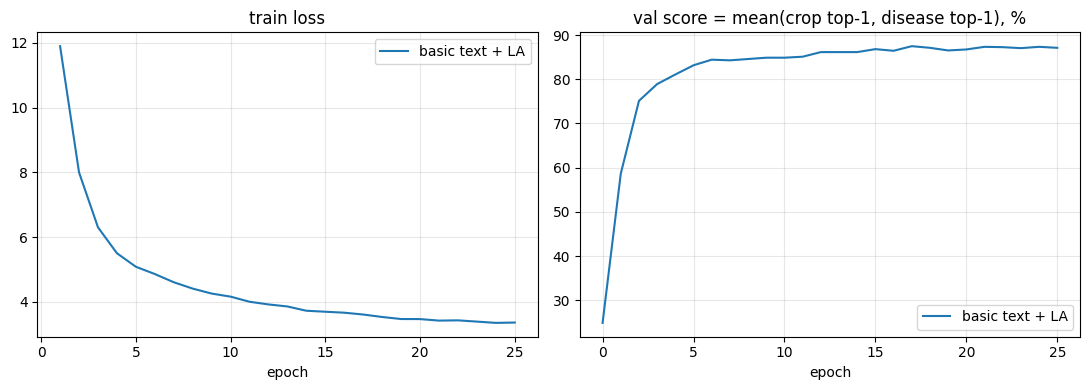

In [16]:
from IPython.display import display
rows = []
for name, r in RES.items():
    s, u = r["test_seen"], r["test_unseen"]
    rows.append({"run": name, "best epoch": r["best_epoch"], "Seen T1": s["top1"], "Unseen T1": u["top1"], "HM T1": r["test_hm_top1"],
                 "Seen T5": s["top5"], "Unseen T5": u["top5"], "Crop acc (U)": u["crop_acc"], "Dis acc (U)": u["disease_acc"],
                 "Bal. unseen": u["class_balanced_acc"], "AUSUC": r["ausuc"]["auc"], "calibrated best HM": r["ausuc"]["best_hm"]})
tab = pd.DataFrame(rows).set_index("run")
pct = [c for c in tab.columns if c != "best epoch"]
tab[pct] = (100 * tab[pct]).round(2)
display(tab)
tab.to_csv(f"{OUT}/results_basic_la.csv")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for exp, lab in (("s2b_bioclip_tax_la", "basic text + LA"),):
    h = pd.read_csv(f"{OUT}/outputs/{exp}/history.csv")
    ax[0].plot(h.epoch[1:], h.train_loss[1:], label=lab); ax[1].plot(h.epoch, 100 * h.val_score, label=lab)
ax[0].set_title("train loss"); ax[1].set_title("val score = mean(crop top-1, disease top-1), %")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
fig.tight_layout(); fig.savefig(f"{OUT}/curves_basic_la.png", dpi=150); plt.show()